# Lab: Relationships Between Categorical Features

Imagine James Cameron has hired you to develop two character profiles for a Titanic movie reboot: one “most likely to survive” and one “least likely to survive.” Support both profiles with passenger data and visualizations, then connect them to real people and their biographies.

These labels describe profiles suggested by observed group survival percentages in this dataset. They are not guaranteed individual outcomes, a validated prediction model, or proof that any feature caused survival.


## Learning goals

- Apply the six-step analysis workflow to categorical comparisons.
- Justify categories created from age and travel-companion counts.
- Distinguish raw counts from survival percentages within groups.
- Build clearly labeled figures and check their meaning.
- Support character profiles with evidence and identify matching passengers.
- Connect data records to cited historical biographies.


## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can help answer it?
3. **Evidence:** What should we calculate and display to answer the question?
4. **Check:** Does the result make sense in context? Do the original values support the coding and interpretation?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Use one six-step workflow for the complete character-profile investigation. All six feature comparisons belong together in Step 3: Evidence.


## Dataset and scope

Use the supplied `data/titanic_passengers.csv`, the 891-row training dataset from [Kaggle Titanic: Machine Learning from Disaster](https://www.kaggle.com/c/titanic/data). Each row represents a passenger in this file; it is not a complete passenger-and-crew list. Consult the source dictionary when interpreting the features.

Analyze only categorical comparisons with `Survived`. Use `Pclass` instead of `Fare`; do not analyze fare. Age is the exception: convert it to justified categories before comparing survival. Treat travel-companion counts as categories, combining sparse groups if appropriate. Use names and passenger IDs only to identify people.

| Feature | Meaning and role |
| --- | --- |
| `Survived` | Categorical outcome: 0 = did not survive, 1 = survived |
| `Pclass` | Ordered passenger class: 1, 2, or 3; categorical despite numeric storage |
| `Sex` | Recorded sex category |
| `Age` | Age in years; use only through your chosen age groups |
| `Parch` | Count of parents/children aboard; use as categories or collapse into groups |
| `SibSp` | Count of siblings/spouse aboard; use as categories or collapse into groups |
| `Embarked` | Embarkation port: C = Cherbourg, Q = Queenstown, S = Southampton |
| `Name`, `PassengerId` | Passenger identification for matching records to biographies |

The file also contains `Ticket`, `Fare`, and `Cabin`; do not use them as comparison features in this lab.


## Using AI tools responsibly

You may use AI for questions, debugging, or feedback. You remain responsible for understanding the code and checking claims against the output. Read the actual Encyclopedia Titanica biographies rather than using an uncited AI-generated fact. Disclose AI use in the final reflection.


## Step 1: Question

**Which categorical characteristics support a “most likely to survive” profile and a “least likely to survive” profile in this Titanic dataset?**

Consider age group, sex, passenger class, parents/children aboard, siblings/spouse aboard, and embarkation port together as parts of this one investigation.


**Before examining survival percentages, describe your predicted high-survival and low-survival profiles. What reasoning or prior knowledge supports your predictions?**

Your answer: I predict the most likely to survive profile is a single young woman. She would be prioritized for a lifeboat by multiple people, since crew members and other passengers would want to help her. She is also young and able-bodied, so she could move quickly and handle the conditions. Her only real weakness is empathy: she might stop to help others instead of saving herself. I predict the least likely to survive profile is a married older man. He would prioritize everyone else, especially his wife, before himself. He would also be physically weaker, and he would likely tell others to leave him behind and save themselves.

## Step 2: Data


## Load and inspect the data

Use `titanic_df` as the DataFrame name. Keep the original columns so your category choices can be checked.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
titanic_df = pd.read_csv("data/titanic_passengers.csv")

In [3]:
titanic_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
titanic_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [5]:
titanic_df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

**What does one row represent? Which feature is the target, and what do its codes mean?**

Your answer: Each row represents one passenger from the Titanic training dataset (891 passengers total, not the full passenger and crew list). The target feature is `Survived`, where 0 means the passenger did not survive and 1 means the passenger survived.

Complete this table from the inspection. Distinguish a feature's meaning from its Pandas storage type; numeric codes can represent categories.


| Feature | Data type (categorical/quantitative/identifier) | Data storage type | Missing values |
| --- | --- | --- | ---: |
| `PassengerId` | Identifier | int64 | 0 |
| `Name` | Identifier | object | 0 |
| `Survived` | Categorical | int64 | 0 |
| `Pclass` | Categorical (ordered) | int64 | 0 |
| `Sex` | Categorical | object | 0 |
| `Age` | Quantitative | float64 | 177 |
| `Parch` | Quantitative (count, used as categories) | int64 | 0 |
| `SibSp` | Quantitative (count, used as categories) | int64 | 0 |
| `Embarked` | Categorical | object | 2 |

## Plan your age groups before comparing survival

Choose your own age categories. You might use children versus adults, split at 16, 18, or 20, or define several groups such as children, teens, young adults, and older adults. There is no single required cutoff. Give a reasoned argument based on the meaning of the groups and their usefulness, not just which split produces the strongest survival difference.

Write exact boundaries, including where an age exactly at a cutoff belongs. Cover all known ages without overlapping groups. Preserve unknown ages as missing or label them “Unknown”; do not accidentally classify them as adults. If you exclude unknown ages from this comparison, state that denominator choice. Do not guess an age from whether someone survived.


| Age-group label | Exact rule (including boundary values) | Reason for this choice |
| --- | --- | --- |
| Child | `Age` < 13 (an age of exactly 13 is a Teen) | Young children were the most likely to be put in a lifeboat under "women and children first." |
| Teen | 13 <= `Age` < 18 (13 is included, 18 is not) | Teenagers were not yet adults but were old enough that they may not have been treated like young children. |
| Adult | 18 <= `Age` < 60 (18 is included, 60 is not) | 18 is a common age for adulthood. This group covers able-bodied adults. |
| Older adult | `Age` >= 60 (60 is included) | My prediction is about an older man, so I need a separate group to check whether older passengers did worse. |
| Unknown | `Age` is missing | 177 passengers have no recorded age, so I cannot place them in an age group. |

Add rows if needed.

**Why are your age groups reasonable? How will you handle unknown ages, and why?**

Your answer: These groups match my prediction, which is about a young person versus an older person, and they follow common life stages (child, teen, adult, older adult). The rules use "less than" for the upper boundary, so ages with decimals like 14.5 or 59.5 still fall into exactly one group and no age is left out. I will keep the 177 passengers with missing ages in an "Unknown" group instead of dropping them or counting them as adults, because guessing their ages could make my comparison wrong. They will still appear in the counts, so the denominator for each age group is all passengers in that group, and the Unknown group is shown separately.

Create `age_group` using `.loc` or `pd.cut`. If using `.loc`, initialize the column to an explicit “Unknown” label and assign labels only where ages satisfy your rules. If using `pd.cut`, choose its interval boundaries carefully and document whether intervals include their right or left endpoint. Count the observations in each category, including unknowns.


In [7]:
titanic_df["age_group"] = "Unknown"
titanic_df.loc[titanic_df["Age"] < 13, "age_group"] = "Child"
titanic_df.loc[(titanic_df["Age"] >= 13) & (titanic_df["Age"] < 18), "age_group"] = "Teen"
titanic_df.loc[(titanic_df["Age"] >= 18) & (titanic_df["Age"] < 60), "age_group"] = "Adult"
titanic_df.loc[titanic_df["Age"] >= 60, "age_group"] = "Older adult"

titanic_df["age_group"].value_counts()

age_group
Adult          575
Unknown        177
Child           69
Teen            44
Older adult     26
Name: count, dtype: int64

**Are any age groups very small? Would a different grouping be more useful? Explain any revision before comparing survival.**

Your answer: The Older adult group is small with only 26 passengers, and the Teen group has 44, compared with 575 Adults and 69 Children. A few passengers in these small groups could change their survival percentages a lot, so I will be careful when interpreting them. I am still keeping them as separate groups because my prediction is about older passengers, and combining them with Adults would hide the comparison I want to make. I did not revise the grouping.

### Choose travel-companion categories

Inspect the frequencies of `Parch` and `SibSp`. Treat their values as discrete categories or collapse them into meaningful groups, such as none/any or none/one/two or more. Explain your choices, particularly when some categories have few passengers. Preserve the original columns.


In [8]:
print(titanic_df["Parch"].value_counts().sort_index())
print(titanic_df["SibSp"].value_counts().sort_index())

titanic_df["parents_children_group"] = titanic_df["Parch"]
titanic_df.loc[titanic_df["Parch"] >= 2, "parents_children_group"] = 2

titanic_df["siblings_spouse_group"] = titanic_df["SibSp"]
titanic_df.loc[titanic_df["SibSp"] >= 2, "siblings_spouse_group"] = 2

print(titanic_df["parents_children_group"].value_counts().sort_index())
print(titanic_df["siblings_spouse_group"].value_counts().sort_index())

Parch
0    678
1    118
2     80
3      5
4      4
5      5
6      1
Name: count, dtype: int64
SibSp
0    608
1    209
2     28
3     16
4     18
5      5
8      7
Name: count, dtype: int64
parents_children_group
0    678
1    118
2     95
Name: count, dtype: int64
siblings_spouse_group
0    608
1    209
2     74
Name: count, dtype: int64


**What travel-companion groups will you use, and why? State any exclusions and how you will handle unknown embarkation ports. Which observations form the denominator for each comparison?**

Your answer: For both `Parch` and `SibSp`, I will use three groups: 0 = None, 1 = One, and 2 = Two or more. Most passengers had 0 or 1, and the higher counts are very small (for example, only 1 passenger had 6 parents/children and only 5 had 5 siblings/spouses), so combining everything 2 and above into one group gives each group enough passengers to compare: 678 / 118 / 95 for parents/children and 608 / 209 / 74 for siblings/spouse. These groups also fit my prediction, since a passenger with no siblings/spouse is closer to "single" and a passenger with one may be traveling with a husband or wife. The original `Parch` and `SibSp` columns are kept. I am not excluding any passengers from the age, sex, class, or travel-companion comparisons, so each of those denominators is all 891 passengers split into their groups (with unknown ages in the Unknown age group). For embarkation port, the 2 passengers with a missing `Embarked` value will be left out because their port is unknown, so that comparison uses 889 passengers.

## Step 3: Evidence

Bring all six feature comparisons together here. For each feature:

- Display a count cross-tab with comparison categories in rows and survival outcomes in columns.
- Calculate survival percentages within each comparison group and display only the percentage who survived (column `1`). Keep group counts available for context.
- Make a bar chart of the conditional percentage who survived, with a meaningful title, descriptive axes, readable category labels, and named colors. Use a 0–100 percentage scale and `plt.legend()` if a legend is needed. Move it outside the axes if it covers the data.

Use separate code cells for the individual operations and add cells as needed. The subsections below organize the evidence; they are not separate workflows.


### Age groups

Compare `age_group` with `Survived` using your Data-step choices.


In [9]:
age_order = ["Child", "Teen", "Adult", "Older adult", "Unknown"]

age_counts = pd.crosstab(titanic_df["age_group"], titanic_df["Survived"]).loc[age_order]
age_counts

Survived,0,1
age_group,,
Child,29,40
Teen,23,21
Adult,353,222
Older adult,19,7
Unknown,125,52


In [10]:
age_percent = pd.crosstab(
    titanic_df["age_group"], titanic_df["Survived"], normalize="index"
).mul(100).round(1).loc[age_order]
age_percent[[1]]

Survived,1
age_group,
Child,58.0
Teen,47.7
Adult,38.6
Older adult,26.9
Unknown,29.4


For age groups, also display joint percentages (`normalize="all"`, multiplied by 100) and make a count chart showing both outcomes. Compare this with the survivor-percentage chart to distinguish counts, joint percentages, and within-group percentages.


In [11]:
pd.crosstab(titanic_df["age_group"], titanic_df["Survived"], normalize="all").mul(100).round(1).loc[age_order]

Survived,0,1
age_group,,
Child,3.3,4.5
Teen,2.6,2.4
Adult,39.6,24.9
Older adult,2.1,0.8
Unknown,14.0,5.8


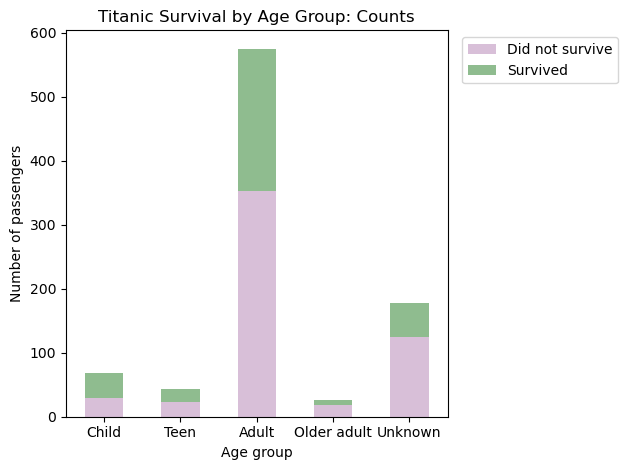

In [12]:
age_counts.plot(kind="bar", stacked=True, color=["thistle", "darkseagreen"])
plt.title("Titanic Survival by Age Group: Counts")
plt.xlabel("Age group")
plt.ylabel("Number of passengers")
plt.xticks(rotation=0)
plt.legend(labels=['Did not survive', 'Survived'], loc="upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

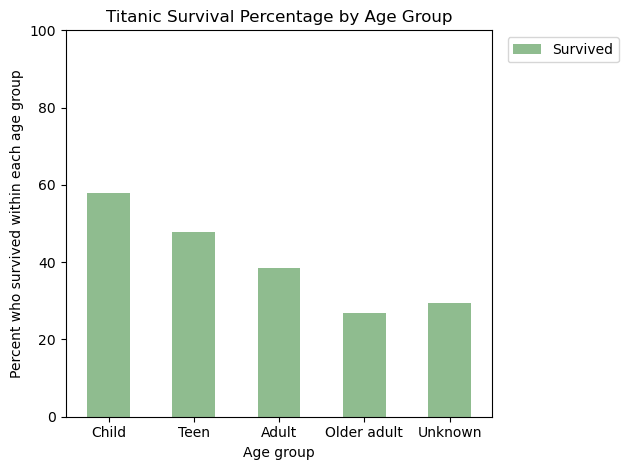

In [13]:
age_percent[1].plot(kind="bar", color="darkseagreen", legend=True)
plt.title("Titanic Survival Percentage by Age Group")
plt.xlabel("Age group")
plt.ylabel("Percent who survived within each age group")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(labels=['Survived'], loc="upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

### Sex

Compare `Sex` with `Survived` using your Data-step choices.


In [14]:
sex_counts = pd.crosstab(titanic_df["Sex"], titanic_df["Survived"])
sex_counts

Survived,0,1
Sex,,
female,81,233
male,468,109


In [15]:
sex_percent = pd.crosstab(
    titanic_df["Sex"], titanic_df["Survived"], normalize="index"
).mul(100).round(1)
sex_percent[[1]]

Survived,1
Sex,
female,74.2
male,18.9


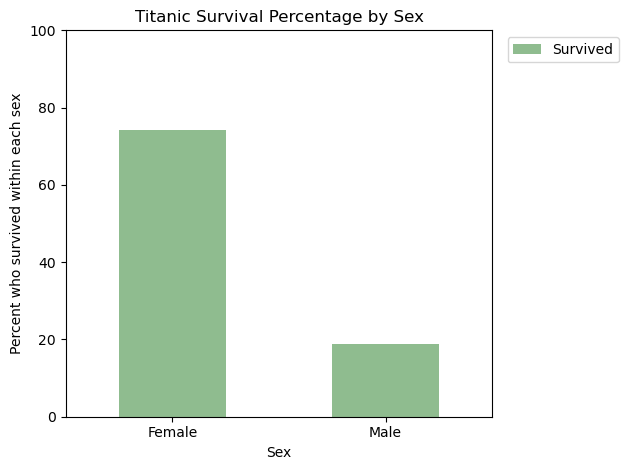

In [16]:
sex_percent[1].plot(kind="bar", color="darkseagreen", legend=True)
plt.title("Titanic Survival Percentage by Sex")
plt.xlabel("Sex")
plt.ylabel("Percent who survived within each sex")
plt.xticks([0, 1], ['Female', 'Male'], rotation=0)
plt.ylim(0, 100)
plt.legend(labels=['Survived'], loc="upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

### Passenger class

Compare `Pclass` with `Survived` using your Data-step choices.


In [17]:
class_counts = pd.crosstab(titanic_df["Pclass"], titanic_df["Survived"])
class_counts

Survived,0,1
Pclass,,
1,80,136
2,97,87
3,372,119


In [18]:
class_percent = pd.crosstab(
    titanic_df["Pclass"], titanic_df["Survived"], normalize="index"
).mul(100).round(1)
class_percent[[1]]

Survived,1
Pclass,
1,63.0
2,47.3
3,24.2


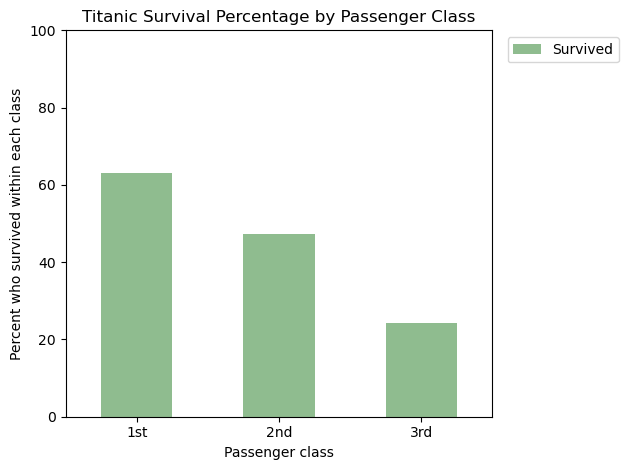

In [19]:
class_percent[1].plot(kind="bar", color="darkseagreen", legend=True)
plt.title("Titanic Survival Percentage by Passenger Class")
plt.xlabel("Passenger class")
plt.ylabel("Percent who survived within each class")
plt.xticks([0, 1, 2], ['1st', '2nd', '3rd'], rotation=0)
plt.ylim(0, 100)
plt.legend(labels=['Survived'], loc="upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

### Parents or children aboard

Compare `parents_children_group` with `Survived` using your Data-step choices.


In [20]:
parch_counts = pd.crosstab(titanic_df["parents_children_group"], titanic_df["Survived"])
parch_counts

Survived,0,1
parents_children_group,,
0,445,233
1,53,65
2,51,44


In [21]:
parch_percent = pd.crosstab(
    titanic_df["parents_children_group"], titanic_df["Survived"], normalize="index"
).mul(100).round(1)
parch_percent[[1]]

Survived,1
parents_children_group,
0,34.4
1,55.1
2,46.3


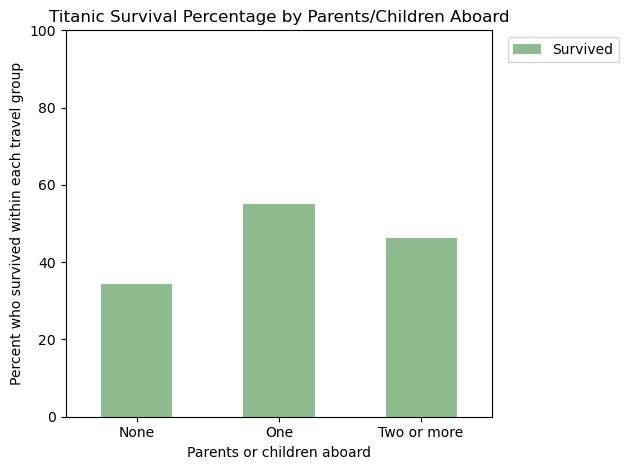

In [22]:
parch_percent[1].plot(kind="bar", color="darkseagreen", legend=True)
plt.title("Titanic Survival Percentage by Parents/Children Aboard")
plt.xlabel("Parents or children aboard")
plt.ylabel("Percent who survived within each travel group")
plt.xticks([0, 1, 2], ['None', 'One', 'Two or more'], rotation=0)
plt.ylim(0, 100)
plt.legend(labels=['Survived'], loc="upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

### Siblings or spouse aboard

Compare `siblings_spouse_group` with `Survived` using your Data-step choices.


In [23]:
sibsp_counts = pd.crosstab(titanic_df["siblings_spouse_group"], titanic_df["Survived"])
sibsp_counts

Survived,0,1
siblings_spouse_group,,
0,398,210
1,97,112
2,54,20


In [24]:
sibsp_percent = pd.crosstab(
    titanic_df["siblings_spouse_group"], titanic_df["Survived"], normalize="index"
).mul(100).round(1)
sibsp_percent[[1]]

Survived,1
siblings_spouse_group,
0,34.5
1,53.6
2,27.0


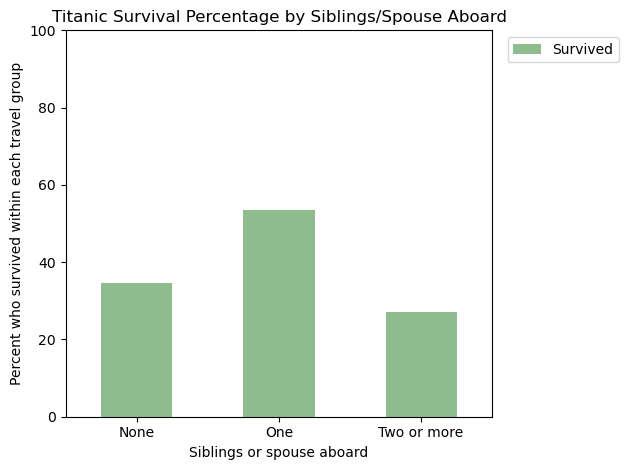

In [25]:
sibsp_percent[1].plot(kind="bar", color="darkseagreen", legend=True)
plt.title("Titanic Survival Percentage by Siblings/Spouse Aboard")
plt.xlabel("Siblings or spouse aboard")
plt.ylabel("Percent who survived within each travel group")
plt.xticks([0, 1, 2], ['None', 'One', 'Two or more'], rotation=0)
plt.ylim(0, 100)
plt.legend(labels=['Survived'], loc="upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

### Embarkation port

Compare `Embarked` with `Survived` using your Data-step choices.


In [26]:
port_counts = pd.crosstab(titanic_df["Embarked"], titanic_df["Survived"])
port_counts

Survived,0,1
Embarked,,
C,75,93
Q,47,30
S,427,217


In [27]:
port_percent = pd.crosstab(
    titanic_df["Embarked"], titanic_df["Survived"], normalize="index"
).mul(100).round(1)
port_percent[[1]]

Survived,1
Embarked,
C,55.4
Q,39.0
S,33.7


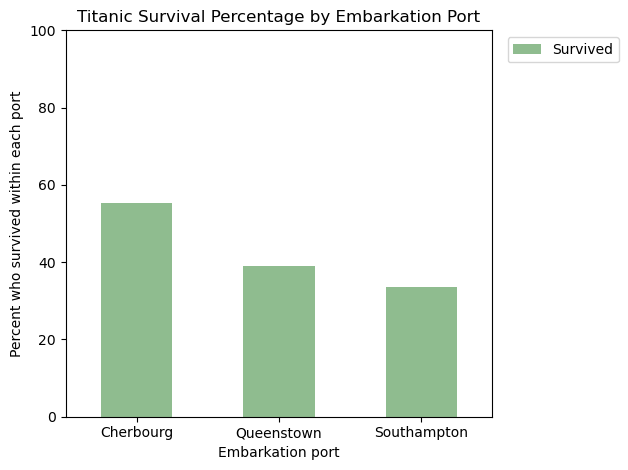

In [28]:
port_percent[1].plot(kind="bar", color="darkseagreen", legend=True)
plt.title("Titanic Survival Percentage by Embarkation Port")
plt.xlabel("Embarkation port")
plt.ylabel("Percent who survived within each port")
plt.xticks([0, 1, 2], ['Cherbourg', 'Queenstown', 'Southampton'], rotation=0)
plt.ylim(0, 100)
plt.legend(labels=['Survived'], loc="upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

### Summarize the evidence

Record the highest- and lowest-survival categories for each feature. Include percentages and group sizes; mention ties or very small groups that affect interpretation.


| Feature | Highest-survival category, percentage, and group size | Lowest-survival category, percentage, and group size |
| --- | --- | --- |
| Sex (example) | Female: 74.2% survived (233 of 314 passengers). | Male: 18.9% survived (109 of 577 passengers). |
| Age groups | Child: 58.0% survived (40 of 69 passengers). | Older adult: 26.9% survived (7 of 26 passengers). This is a small group. Unknown age was close behind at 29.4% (52 of 177). |
| Passenger class | 1st class: 63.0% survived (136 of 216 passengers). | 3rd class: 24.2% survived (119 of 491 passengers). |
| Parents or children aboard | One: 55.1% survived (65 of 118 passengers). | None: 34.4% survived (233 of 678 passengers). |
| Siblings or spouse aboard | One: 53.6% survived (112 of 209 passengers). | Two or more: 27.0% survived (20 of 74 passengers). None was close at 34.5% (210 of 608). |
| Embarkation port | Cherbourg: 55.4% survived (93 of 168 passengers). | Southampton: 33.7% survived (217 of 644 passengers). |

**Using the age comparison, interpret one joint percentage and one conditional percentage. What denominator does each use, and which figure answers the survival-likelihood question more clearly?**

Your answer: The joint percentage for children who survived is 4.5%. This uses all 891 passengers as the denominator, so it means 40 surviving children make up 4.5% of everyone in the dataset. The conditional percentage for children is 58.0%, which uses only the 69 children as the denominator, so it means 58.0% of children survived. The conditional percentage answers the survival-likelihood question more clearly, because the joint percentage is mostly small just because there are few children in the dataset. For example, surviving adults have a much larger joint percentage (24.9%) than surviving children (4.5%), even though a lower share of adults survived (38.6% compared with 58.0%).

## Step 4: Check

Check the meaning of your combined evidence, rather than repeating the initial row count or missing-value inspection.

- Compare each age group's minimum and maximum known ages with your declared boundaries, including exact cutoffs and unknown ages.
- If you collapsed travel-companion categories, cross-tab the original counts against your group labels.
- Check that percentages use all passengers in the relevant group, not just survivors. Compare the direction of the percentages with the count tables.
- Identify sparse groups or implausible values that deserve caution.


In [29]:
print(titanic_df.groupby("age_group")["Age"].agg(["min", "max", "count", "size"]).loc[age_order])
print(titanic_df.loc[titanic_df["Age"].isnull(), "age_group"].value_counts())

               min   max  count  size
age_group                            
Child         0.42  12.0     69    69
Teen         13.00  17.0     44    44
Adult        18.00  59.0    575   575
Older adult  60.00  80.0     26    26
Unknown        NaN   NaN      0   177
age_group
Unknown    177
Name: count, dtype: int64


In [30]:
print(pd.crosstab(titanic_df["Parch"], titanic_df["parents_children_group"]))
print(pd.crosstab(titanic_df["SibSp"], titanic_df["siblings_spouse_group"]))

parents_children_group    0    1   2
Parch                               
0                       678    0   0
1                         0  118   0
2                         0    0  80
3                         0    0   5
4                         0    0   4
5                         0    0   5
6                         0    0   1
siblings_spouse_group    0    1   2
SibSp                              
0                      608    0   0
1                        0  209   0
2                        0    0  28
3                        0    0  16
4                        0    0  18
5                        0    0   5
8                        0    0   7


**Do the age boundaries, category mappings, and denominators match your intentions? What would make you suspicious, and did you find or correct any issues? Which small groups limit interpretation?**

Your answer: Yes, everything matches what I planned. Each age group's minimum and maximum ages stay inside its boundaries: Child is 0.42 to 12, Teen is 13 to 17, Adult is 18 to 59, and Older adult is 60 to 80. All 177 passengers with a missing age are in the Unknown group, and none of them were put in Adult by accident. The travel-companion cross-tabs show that 0 maps to None, 1 maps to One, and every value from 2 up (2 through 6 for `Parch`, 2 through 8 for `SibSp`) maps to Two or more, with nothing in the wrong group. The percentages use everyone in each group, not just survivors. For example, 40 of the 69 children survived, which is the 58.0% in the percentage table, and every group with more survivors than non-survivors in the count table also has a survival percentage above 50%. I would have been suspicious if an age group's max was above its cutoff, if Unknown had fewer than 177 passengers, or if any percentages in a row did not make sense with the counts, but I did not find any issues to fix. The Older adult group (26 passengers), Teen group (44), and siblings/spouse Two or more group (74) are small, so a few passengers could change their percentages a lot, and I will be careful when using them in my profiles.

## Step 5: Conclusion

Use the combined evidence to develop the two profiles, find matching passengers, and connect them to historical biographies.


### Build your two character profiles

Combine the evidence into a “most likely to survive” profile and a “least likely to survive” profile. Include all six elements. Cite the relevant group percentage and size for each choice. Do not multiply separate feature percentages to produce an individual survival probability: the features may be related, and separate comparisons do not establish the survival rate for their combination.


| Profile element | Most likely profile: category and evidence | Least likely profile: category and evidence |
| --- | --- | --- |
| Sex (example) | Female: 74.2% survived (233 of 314 passengers). | Male: 18.9% survived (109 of 577 passengers). |
| Age groups | Teen (revised from Child): 47.7% survived (21 of 44 passengers). Child was highest at 58.0% (40 of 69). | Older adult: 26.9% survived (7 of 26 passengers). |
| Passenger class | 1st class: 63.0% survived (136 of 216 passengers). | 3rd class: 24.2% survived (119 of 491 passengers). |
| Parents or children aboard | One: 55.1% survived (65 of 118 passengers). | None: 34.4% survived (233 of 678 passengers). |
| Siblings or spouse aboard | None (revised from One): 34.5% survived (210 of 608 passengers). One was highest at 53.6% (112 of 209). | None (revised from Two or more): 34.5% survived (210 of 608 passengers). Two or more was lowest at 27.0% (20 of 74). |
| Embarkation port | Cherbourg: 55.4% survived (93 of 168 passengers). | Southampton: 33.7% survived (217 of 644 passengers). |

**Write a short character description for each profile. Explain any tradeoffs where the evidence does not point to a single obvious combination.**

Your answer: My most likely to survive character is a teenage girl traveling in first class with one parent and no siblings or spouse, who boarded at Cherbourg. She is a single young lady, like I predicted, and as a first-class passenger she would have been close to the lifeboats. My least likely to survive character is an older man (60 or older) traveling alone in third class, with no family aboard, who boarded at Southampton. He was far from the lifeboats and had no family with him to help him or to make sure he got into a boat. The evidence did not point to one perfect combination. My first most likely profile was a female child with one parent and one sibling or spouse, but no passenger in the dataset matched it, so I changed it to a teen with no siblings or spouse. Teen still had the second-highest age survival (47.7%), but no siblings or spouse (34.5%) is much lower than having one (53.6%). I also predicted a married old man would be least likely to survive, but the data showed that passengers with one sibling or spouse actually survived more often (53.6%) than passengers with none (34.5%), so being alone fits the least likely profile better than being married.

### Find real passengers who fit

Use Boolean conditions with `.loc` to find passengers matching each profile across all six elements. Save the results as `most_likely_df` and `least_likely_df`, and display their names and the features used to match them. **Do not filter on `Survived` to build these lists**: an actual outcome is not a profile characteristic.

If a list is empty, explain which combination has no matching record, then revise and justify your profile transparently using the evidence. Keep all six elements in your revised profile, update the profile table, and rerun the filter. Do not silently drop a condition or invent a passenger. You need at least one matching person in each list.


In [ ]:
most_likely_df = titanic_df.loc[
    (titanic_df["Sex"] == "female")
    & (titanic_df["age_group"] == "Teen")
    & (titanic_df["Pclass"] == 1)
    & (titanic_df["parents_children_group"] == 1)
    & (titanic_df["siblings_spouse_group"] == 0)
    & (titanic_df["Embarked"] == "C")
]
most_likely_df[["PassengerId", "Name", "Sex", "Age", "age_group", "Pclass", "Parch", "SibSp", "Embarked"]]

In [ ]:
least_likely_df = titanic_df.loc[
    (titanic_df["Sex"] == "male")
    & (titanic_df["age_group"] == "Older adult")
    & (titanic_df["Pclass"] == 3)
    & (titanic_df["parents_children_group"] == 0)
    & (titanic_df["siblings_spouse_group"] == 0)
    & (titanic_df["Embarked"] == "S")
]
least_likely_df[["PassengerId", "Name", "Sex", "Age", "age_group", "Pclass", "Parch", "SibSp", "Embarked"]]

**How do your filters match the six profile choices? Document any revisions needed to obtain real matches.**

Your answer: Each filter has one condition for each of the six profile elements: `Sex`, `age_group`, `Pclass`, `parents_children_group`, `siblings_spouse_group`, and `Embarked`. Neither filter uses `Survived`. My original profiles did not match anyone, so I revised one or two elements in each. For the most likely profile, I first used female, Child, 1st class, one parent/child, one sibling/spouse, and Cherbourg. The only female child in first class was Helen Loraine Allison, who had two parents/children aboard and boarded at Southampton, so there was no match. Changing only the age group to Adult would have given three matches, but I chose Teen instead because teens had a higher survival percentage than adults (47.7% compared with 38.6%) and it fits my "single young lady" prediction. To get a match as a Teen, I also had to change siblings/spouse from One to None. This gives one match, Jean Gertrude Hippach. For the least likely profile, I first used Two or more siblings/spouse, but none of the four older men in third class had any siblings or spouse aboard. I changed it to None, which has the next-lowest survival percentage (34.5%), and this gives two matches: Johan Hansen Nysveen and Johan Svensson. I updated the profile table to show these revisions.

### Connect the records to people

Choose one person from `most_likely_df` and one from `least_likely_df`. Find each person on [Encyclopedia Titanica](https://www.encyclopedia-titanica.org/) using its passenger lists or biography search. Check identifying details to make sure you found the same person; names can have spelling variations.

For each person, select at least one interesting fact from the biography beyond the values already listed in your dataset. Describe it in your own words and link directly to the biography. Do not substitute an uncited fact or just restate survival status.


**Who did you choose from your “most likely to survive” list? Give the dataset name and PassengerId, explain how you matched the biography, describe an interesting fact, and provide the direct Encyclopedia Titanica biography URL.**

Your answer: I chose Hippach, Miss. Jean Gertrude (PassengerId 330), the only passenger in `most_likely_df`. I matched her to her Encyclopedia Titanica biography using her name, her ticket number (111361), and her cabin (B18), which are the same in the dataset and the biography. The biography also says she boarded at Cherbourg in first class with her mother, who is in the dataset as PassengerId 524. That matches her `Parch` value of 1 and `SibSp` value of 0. An interesting fact is that Jean and her mother did not get into the first lifeboats because they thought they were safer staying on the Titanic. While they were walking past Lifeboat 4 as it was being loaded, Colonel John Jacob Astor told them to get in, and her mother later credited him with saving their lives. I think it's great that a colonel was the one who saved her, especially since Astor himself did not survive.

Biography: [Jean Gertrude Hippach on Encyclopedia Titanica](https://www.encyclopedia-titanica.org/titanic-survivor/jean-gertrude-hippach.html)

**Who did you choose from your “least likely to survive” list? Give the dataset name and PassengerId, explain how you matched the biography, describe an interesting fact, and provide the direct Encyclopedia Titanica biography URL.**

Your answer: I chose Svensson, Mr. Johan (PassengerId 852) from `least_likely_df`. I matched him to his Encyclopedia Titanica biography using his name, his ticket number (347060), and his age of 74, which are the same in the dataset and the biography. The biography also says he was a third-class passenger who boarded at Southampton, which matches the dataset. An interesting fact is that he was the oldest person aboard the Titanic. He was a farmer from Sweden whose wife had died a couple of months earlier, and he was traveling to South Dakota to live with family.

Biography: [Johan Svensson on Encyclopedia Titanica](https://www.encyclopedia-titanica.org/titanic-victim/johan-svensson.html)

After choosing the people, compare their recorded survival outcomes with their profiles. A passenger can contradict a group tendency. If the biography conflicts with this dataset, report the disagreement and what the sources say rather than silently changing the data.


In [ ]:
titanic_df.loc[
    titanic_df["PassengerId"].isin([330, 852]),
    ["PassengerId", "Name", "Sex", "Age", "age_group", "Pclass", "Parch", "SibSp", "Embarked", "Survived"]
]

**Did each person's actual outcome align with the profile label? What does this show about using group patterns to describe individuals? Note any discrepancies with the biographies.**

Your answer: Yes, both outcomes matched their profile labels. Jean Hippach survived (`Survived` = 1), and Johan Svensson did not survive (`Survived` = 0). This does not mean the profiles predict what happens to every individual. A group pattern only describes what happened to most people in a group, and individuals can go against it. For example, Helen Loraine Allison (PassengerId 298) was a female child in first class, which fits many of the high-survival categories, but she did not survive. Jean also might not have survived if Colonel Astor had not told her and her mother to get into Lifeboat 4. I found some discrepancies between the biographies and the dataset. Jean's biography gives her birth date as 1 October 1894, which would make her 17, but the dataset lists her age as 16. The biography also says her birth date is disputed, so either age could be right. Svensson's biography says his son, Johan Ekström, was traveling with him and also died. Ekström is in the dataset (PassengerId 130), but both men have `Parch` = 0, so the dataset does not show that they were traveling together. They had different ticket numbers (347060 and 347061), which may be why. Svensson's biography also says he was the oldest person aboard at 74, but the dataset lists Algernon Henry Wilson Barkworth (PassengerId 631) as 80. One of these sources may be wrong, so I did not change any values in the dataset.

### Final recommendation to the director


**Recommend the two characters using numerical evidence and their biographical facts. How do your completed profiles compare with your initial predictions? Explain any tradeoffs or revisions.**

Your answer: I recommend Jean Gertrude Hippach as the "most likely to survive" character and Johan Svensson as the "least likely to survive" character. Jean fits a profile where most of the categories had high survival percentages: females (74.2% survived, 233 of 314), first class (63.0%, 136 of 216), one parent or child aboard (55.1%, 65 of 118), and Cherbourg (55.4%, 93 of 168). Teens were also above average at 47.7% (21 of 44). Her story would make a great movie scene, because she and her mother first stayed on the ship thinking it was safer, until Colonel John Jacob Astor told them to get into Lifeboat 4. Svensson fits a profile where every category had low survival: males (18.9%, 109 of 577), older adults (26.9%, 7 of 26), third class (24.2%, 119 of 491), no parents or children aboard (34.4%, 233 of 678), no siblings or spouse aboard (34.5%, 210 of 608), and Southampton (33.7%, 217 of 644). As the oldest person aboard, traveling in third class to start a new life in America, he would be a memorable character. My final profiles mostly matched my predictions: a young woman was most likely to survive and an older man was least likely. However, I predicted that being single would help the young woman and being married would hurt the older man, and the data showed the opposite: passengers with one sibling or spouse survived more often (53.6%) than passengers with none (34.5%). I also had to revise both profiles because my first combinations did not match any real passengers. For Jean's profile I changed Child to Teen and One sibling/spouse to None. For Svensson's profile I changed Two or more siblings/spouse to None.

## Step 6: Limitation


**What should the director avoid concluding? Discuss why separate feature comparisons do not establish an individual survival probability or causation, and address relevant limitations such as small groups, missing ages, category choices, or uncertain historical records.**

Your answer: The director should not conclude that Jean was guaranteed to survive or that Svensson was guaranteed to die because of their profiles. Each survival percentage comes from comparing one feature at a time, so the percentages cannot be multiplied together to get one person's chance of survival. The features are also related to each other. For example, my first profiles did not match any real passengers, and the only female child in first class was Helen Loraine Allison, who did not survive. This shows that the categories do not combine evenly, so the survival rate for a full combination of features can be very different from the separate percentages. These comparisons also do not prove that any feature caused survival; they only show what happened to the passengers in each group. Some groups are small, like older adults (26 passengers) and teens (44), so a few people could change those percentages a lot. 177 passengers had no recorded age and were left in an "Unknown" group, which could change the age results if their real ages were known. My age groups and travel-companion groups were my own choices, and different cutoffs could give different results. The dataset only has 891 passengers and does not include the full passenger list or the crew. Finally, the historical records do not always agree with the dataset. Jean's biography gives her age as 17 instead of 16, Svensson's traveling companion is not shown in `Parch`, and the biography calls Svensson the oldest person aboard even though the dataset lists someone who is 80.

## AI-use reflection


**Did you use AI? If so, describe one suggestion you checked and accepted, modified, or rejected. If not, state that you did not use it.**

Your answer: Yes, I used AI (Claude) while working on this lab. One suggestion I checked and accepted was about discrepancies between the dataset and the Encyclopedia Titanica biographies. The AI pointed out that Johan Svensson's biography says his son, Johan Ekström, was traveling with him and also died, but both men have `Parch` = 0 in the dataset. I checked this by looking up both passengers in the dataset (PassengerIds 852 and 130) and reading Svensson's biography. I found that they had different ticket numbers (347060 and 347061), which may be why the dataset doesn't link them. The AI also pointed out that the biography calls Svensson the oldest person aboard at 74, but the dataset lists a passenger who is 80. I accepted both points and included them in my discrepancy answer, but I did not change any values in the dataset because I can't tell which source is correct.

## Submission checklist

- Complete one six-step workflow with an initial prediction and evidence for all six profile elements.
- Justify age boundaries and missing-age handling; use passenger class, not fare.
- Include a labeled visualization for every profile element and the age count-versus-percentage comparison.
- Support both complete profiles with group percentages and sizes.
- Display both matching-passenger lists and select one real person from each.
- Include an interesting fact and direct Encyclopedia Titanica biography link for each selected person.
- Complete the combined conclusion, limitation, and AI-use reflection.
- Restart the kernel and run all cells in order; check that claims match the output.
